# Part 11: Error Bars on the Rest of Part 2

Part 2 produced nine numbered claims and a six-column summary table. Every one of them came from
**one simulated dataset** — `DATA_SEED = 42` — averaged over ten particle-filter seeds. That design
averages away the filter's own Monte Carlo noise and leaves the *dataset's* contribution untouched,
so a quantity that happens to be unusual on seed 42 stays unusual however many filter seeds are
added.

Part 3 re-tested three of those claims over 30 independent datasets. One of the three needed
correcting: "the three regimes perform almost identically relative to posterior width" became
"`M < d` is genuinely ~40% worse", with every pairwise difference statistically clear. **One claim in
three did not survive**, which is the reason this notebook exists.

| Part 2 claim | status before this notebook |
|---|---|
| Error stays flat over `T` | tested in Part 3 (and Parts 6, 8, 10) — confirmed |
| Regimes near-identical relative to posterior width | tested in Part 3 — **corrected** |
| Degeneracy is driven by the likelihood's sharpness | tested in Part 3 — confirmed, re-attributed |
| The `O(1/\sqrt N)` rate survives in every regime | **one dataset** — Section 2 below |
| `M < d` costs a constant factor of roughly `2\times` | **one dataset** — Section 2 below |
| The `M < d` error concentrates in the unmeasured coordinates, at `2.6\times` | **one dataset** — Section 3 |
| The `M < d` cloud is *healthier*: min ESS `82.7` against `29.3` and `15.6` | **one dataset** — Section 4 |
| Growing `d` at `M = 1` leaves the cloud healthy and the gap creeping to `0.064`, then flat | **one dataset** — Section 5 |
| The summary table (`mean gap`, `max gap`, `min ESS`, resampling count, spread) | **one dataset** — Section 6 |

### Method, identical to Part 3's

30 independent datasets, `data_seed = 100 + k` and `pf_seed = k` for `k = 0..29`, so each dataset is
paired with its own filter seed and the two sources of noise are not confounded. Reported as the mean
with a 95% confidence interval, and compared with Welch's two-sample `t` where a claim is a
comparison. `T = 100` and `N = 1000` throughout, matching Part 2 exactly, so the only change is the
number of datasets.

Where a claim concerns the *shape* of a curve — a slope, a ratio, a flattening — the quantity is
fitted **per dataset** and the 30 fits are summarised. That is a paired design: it uses each
dataset as its own control and is strictly better than fitting one line through 30-dataset averages,
which would hide the thing being tested.

### One addition beyond error bars

Part 9 established that the mean gap is the wrong metric in principle — unbounded, and not what the
theory bounds — and Part 10 showed that averaging a single number over all directions can hide a
failure confined to a few of them. Section 7 therefore re-scores the three regimes with the
Kolmogorov distance, to ask whether any verdict here depends on the metric Part 2 happened to use.

In [1]:
import sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt

import pathlib as _pl
_root = _pl.Path.cwd()
while not (_root / "filters.py").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))   # repo root, from this notebook's folder
from filters import (build_model, run_case, simulate_data_md, kalman_filter_md,
                     particle_filter_md, pf_kf_gap, unit_directions,
                     weighted_ks_vs_gaussian)

QUICK = False            # smoke-test switch: fewer datasets, changes no conclusion

N_DATASETS = 30 if not QUICK else 4
T          = 100
N_PART     = 1000
N_GRID     = [50, 200, 1000, 5000] if not QUICK else [50, 500]
D_GRID     = [1, 2, 4, 8, 16] if not QUICK else [1, 4]
CASES      = [(2, 2, "M = d"), (2, 4, "M > d"), (4, 2, "M < d")]
CASE_COLOR = {"M = d": "tab:blue", "M > d": "tab:green", "M < d": "tab:red"}

# Part 2's own single-dataset numbers, quoted here so every section can print the
# comparison rather than asking the reader to look them up.
PART2 = {
    "slope":   {"M = d": -0.512, "M > d": -0.520, "M < d": -0.507},
    "mean_gap": {"M = d": 0.0371, "M > d": 0.0297, "M < d": 0.0628},
    "max_gap":  {"M = d": 0.1736, "M > d": 0.1245, "M < d": 0.1619},
    "min_ess":  {"M = d": 29.3, "M > d": 15.6, "M < d": 82.7},
    "resamp":   {"M = d": 69.0, "M > d": 97.0, "M < d": 77.0},
    "post_sd":  {"M = d": 0.7501, "M > d": 0.5924, "M < d": 1.1040},
    "rel_gap":  {"M = d": 0.0495, "M > d": 0.0502, "M < d": 0.0568},
}

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Same spurious NumPy 2.0 + Apple Accelerate matmul warnings Parts 2, 3 and 10
# documented: they fire on finite, order-one inputs out of the SIMD path.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
np.seterr(divide="ignore", over="ignore", invalid="ignore")


def ci95(a):
    """Half-width of a 95% confidence interval for the mean of a sample."""
    a = np.asarray(a, dtype=float)
    return 1.96 * a.std(ddof=1) / np.sqrt(len(a))


def welch(a, b):
    """Welch's t statistic and degrees of freedom for two unpaired samples."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    t = (a.mean() - b.mean()) / np.sqrt(va + vb)
    dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    return float(t), float(dof)


def ttest1(a, mu):
    """One-sample t statistic for the mean of `a` against `mu`."""
    a = np.asarray(a, float)
    return float((a.mean() - mu) / (a.std(ddof=1) / np.sqrt(len(a))))


print(f"datasets={N_DATASETS}  T={T}  N={N_PART}  QUICK={QUICK}")
print("|t| > 2.04 is significant at 5% with 29 degrees of freedom; "
      "|t| > 2.76 at 1%.")

datasets=30  T=100  N=1000  QUICK=False
|t| > 2.04 is significant at 5% with 29 degrees of freedom; |t| > 2.76 at 1%.


---
## Section 1 — The baseline: 30 datasets at Part 2's own settings

Before testing any claim about shape, this runs the three regimes exactly as Part 2 did, 30 times
over, and records everything `summarise_case` reports. Every later section draws on these runs, so
they are computed once.

The first thing worth looking at is not any mean but the **spread**: how far a single dataset can
land from the 30-dataset average tells us directly how much a one-dataset claim was worth.

In [2]:
t0 = time.time()
base = {}
for d, M, label in CASES:
    runs = [run_case(d, M, N=N_PART, T=T, data_seed=100 + k, pf_seed=k)
            for k in range(N_DATASETS)]
    base[label] = {
        "mean_gap": np.array([r["mean_gap"] for r in runs]),
        "max_gap":  np.array([r["max_gap"] for r in runs]),
        "min_ess":  np.array([r["min_ess"] for r in runs]),
        "mean_ess": np.array([r["mean_ess"] for r in runs]),
        "post_sd":  np.array([r["post_sd"] for r in runs]),
        "rel_gap":  np.array([r["rel_gap"] for r in runs]),
        "resamp":   np.array([float(r["resampled"].sum()) for r in runs]),
    }
print(f"{3 * N_DATASETS} runs in {time.time()-t0:.1f}s\n")

print("how much does one dataset tell you? spread of each quantity over the 30")
print(f"{'quantity':>9} {'case':>6} {'mean':>9} {'95% CI':>9} {'sd/mean':>8} "
      f"{'min':>9} {'max':>9} {'max/min':>8}")
for key in ("mean_gap", "max_gap", "min_ess", "mean_ess", "post_sd", "rel_gap", "resamp"):
    for _, _, label in CASES:
        v = base[label][key]
        print(f"{key:>9} {label:>6} {v.mean():>9.4f} {ci95(v):>9.4f} "
              f"{v.std(ddof=1)/abs(v.mean()):>8.3f} {v.min():>9.4f} {v.max():>9.4f} "
              f"{v.max()/v.min():>8.2f}")
    print()

print("note. `post_sd` has zero spread across datasets, and that is not a fluke: the")
print("Kalman covariance recursion never reads the data, as Part 10 Section 1 checks")
print("explicitly. The posterior's width is a property of (F, Q, H, R) alone, so it is")
print("the one row of Part 2's table that one dataset established exactly. Every other")
print("row is a sample statistic and is excluded from nothing.")

90 runs in 1.0s

how much does one dataset tell you? spread of each quantity over the 30
 quantity   case      mean    95% CI  sd/mean       min       max  max/min
 mean_gap  M = d    0.0414    0.0013    0.088    0.0354    0.0487     1.38
 mean_gap  M > d    0.0349    0.0013    0.107    0.0284    0.0437     1.54
 mean_gap  M < d    0.0855    0.0033    0.108    0.0687    0.1047     1.52

  max_gap  M = d    0.2378    0.0320    0.376    0.1102    0.4807     4.36
  max_gap  M > d    0.2505    0.0445    0.497    0.0973    0.7080     7.27
  max_gap  M < d    0.3029    0.0403    0.372    0.1751    0.7464     4.26

  min_ess  M = d   21.0803    4.2576    0.564    4.0033   46.1179    11.52
  min_ess  M > d   12.3455    3.6010    0.815    2.3321   48.7418    20.90
  min_ess  M < d   24.1752    4.5020    0.520    8.0125   54.4246     6.79

 mean_ess  M = d  354.9186    3.9964    0.031  322.3307  377.5387     1.17
 mean_ess  M > d  273.7484    4.4160    0.045  242.8806  304.8129     1.25
 mean_es

**Conclusion of Section 1.** The spread across datasets settles how much Part 2's design could have
established, and it varies enormously by quantity:

| quantity | sd / mean | max / min over 30 datasets |
|---|---|---|
| `mean ess` | 0.030–0.045 | 1.13–1.25 |
| `resampled` | 0.016–0.040 | 1.08–1.18 |
| `mean gap`, `rel gap` | 0.088–0.108 | 1.38–1.54 |
| `max gap` | 0.372–0.497 | **4.26–7.27** |
| `min ess` | 0.520–0.815 | **6.79–20.90** |

Two groups, an order of magnitude apart. Time-averaged quantities — the mean gap, the mean ESS, the
resampling count — vary by 3–11% and a single dataset estimates them tolerably. The two
**extreme-value** quantities, the maximum gap and the minimum ESS, vary by 37–82%, and across 30
datasets the minimum ESS spans a factor of up to **20.9**. Those are the two rows of Part 2's table
that one dataset could not support, and `min ESS` carried one of Part 2's headline claims.

`post_sd` has exactly zero spread, and that is the one row a single dataset established perfectly:
the Kalman covariance recursion never reads the data, which Part 10 Section 1 checks to bit
equality. It is worth noticing what this implies about the design — the *difficulty* of each regime
was known exactly from `(F, Q, H, R)`, and only the filter's performance on it needed averaging.

---
## Section 2 — The `O(1/\sqrt N)` rate, and the "constant factor" claim

Part 2's cleanest structural claim was that being under-observed costs a **constant factor** rather
than a worse convergence rate:

> The `O(1/\sqrt N)` rate survives in every regime — fitted slopes `-0.512`, `-0.520`, `-0.507`.
> Being under-observed costs a constant factor of roughly `2\times`, **not a worse convergence
> rate**. This is a critical distinction: a worse constant is merely expensive, a worse rate would
> be fatal.

Those three slopes were single numbers from a single dataset, fitted through four points. Here the
slope is fitted **per dataset**, giving 30 slopes per regime, which makes three things testable that
were not before: whether the mean slope differs from `-0.5`, whether it differs *between* regimes,
and whether the `M < d` penalty is actually constant in `N`.

In [3]:
t0 = time.time()
gaps_N = {label: np.zeros((N_DATASETS, len(N_GRID))) for _, _, label in CASES}
for d, M, label in CASES:
    for j, N in enumerate(N_GRID):
        for k in range(N_DATASETS):
            gaps_N[label][k, j] = run_case(d, M, N=N, T=T, data_seed=100 + k,
                                           pf_seed=k)["mean_gap"]
print(f"{3 * N_DATASETS * len(N_GRID)} runs in {time.time()-t0:.1f}s\n")

logN = np.log(N_GRID)
slopes = {label: np.array([np.polyfit(logN, np.log(gaps_N[label][k]), 1)[0]
                           for k in range(N_DATASETS)])
          for _, _, label in CASES}

print("slope in log N, fitted per dataset")
print(f"{'case':>6} {'Part 2':>8} {'mean':>8} {'95% CI':>8} {'min':>8} {'max':>8} "
      f"{'t vs -0.5':>10}")
for _, _, label in CASES:
    s = slopes[label]
    print(f"{label:>6} {PART2['slope'][label]:>8.3f} {s.mean():>8.4f} {ci95(s):>8.4f} "
          f"{s.min():>8.3f} {s.max():>8.3f} {ttest1(s, -0.5):>10.2f}")

print("\npairwise comparison of the slopes (is the RATE different between regimes?)")
for i in range(3):
    for j in range(i + 1, 3):
        a, b = CASES[i][2], CASES[j][2]
        t, dof = welch(slopes[a], slopes[b])
        print(f"  {a} vs {b}: difference {slopes[a].mean()-slopes[b].mean():+.4f}, "
              f"|t| = {abs(t):.2f} on {dof:.0f} df")

print("\nis the M < d penalty a CONSTANT factor? ratio of mean gaps at each N")
print(f"{'N':>6} {'M<d / M=d':>12} {'95% CI':>8} {'M<d / M>d':>12} {'95% CI':>8}")
rat1, rat2 = [], []
for j, N in enumerate(N_GRID):
    r1 = gaps_N["M < d"][:, j] / gaps_N["M = d"][:, j]
    r2 = gaps_N["M < d"][:, j] / gaps_N["M > d"][:, j]
    rat1.append(r1); rat2.append(r2)
    print(f"{N:>6} {r1.mean():>12.3f} {ci95(r1):>8.3f} {r2.mean():>12.3f} {ci95(r2):>8.3f}")
# A constant factor means the ratio does not trend with N: fit it.
sl1 = np.polyfit(logN, [r.mean() for r in rat1], 1)[0]
sl2 = np.polyfit(logN, [r.mean() for r in rat2], 1)[0]
print(f"\ntrend of the ratio in log N: {sl1:+.4f} per e-fold (vs M=d), "
      f"{sl2:+.4f} (vs M>d)")
print("paired t across datasets, ratio at N = max against ratio at N = min:")
for nm, r in (("vs M=d", rat1), ("vs M>d", rat2)):
    dif = r[-1] - r[0]
    print(f"  {nm}: mean change {dif.mean():+.4f}, "
          f"t = {dif.mean()/(dif.std(ddof=1)/np.sqrt(len(dif))):+.2f}")

360 runs in 4.9s

slope in log N, fitted per dataset
  case   Part 2     mean   95% CI      min      max  t vs -0.5
 M = d   -0.512  -0.5027   0.0057   -0.531   -0.478      -0.92
 M > d   -0.520  -0.5034   0.0090   -0.550   -0.456      -0.74
 M < d   -0.507  -0.4745   0.0108   -0.560   -0.407       4.63

pairwise comparison of the slopes (is the RATE different between regimes?)
  M = d vs M > d: difference +0.0007, |t| = 0.13 on 49 df
  M = d vs M < d: difference -0.0282, |t| = 4.53 on 44 df
  M > d vs M < d: difference -0.0289, |t| = 4.04 on 56 df

is the M < d penalty a CONSTANT factor? ratio of mean gaps at each N
     N    M<d / M=d   95% CI    M<d / M>d   95% CI
    50        1.928    0.094        2.163    0.097
   200        2.021    0.080        2.397    0.120
  1000        2.076    0.092        2.469    0.121
  5000        2.227    0.139        2.490    0.108

trend of the ratio in log N: +0.0617 per e-fold (vs M=d), +0.0672 (vs M>d)
paired t across datasets, ratio at N = max a

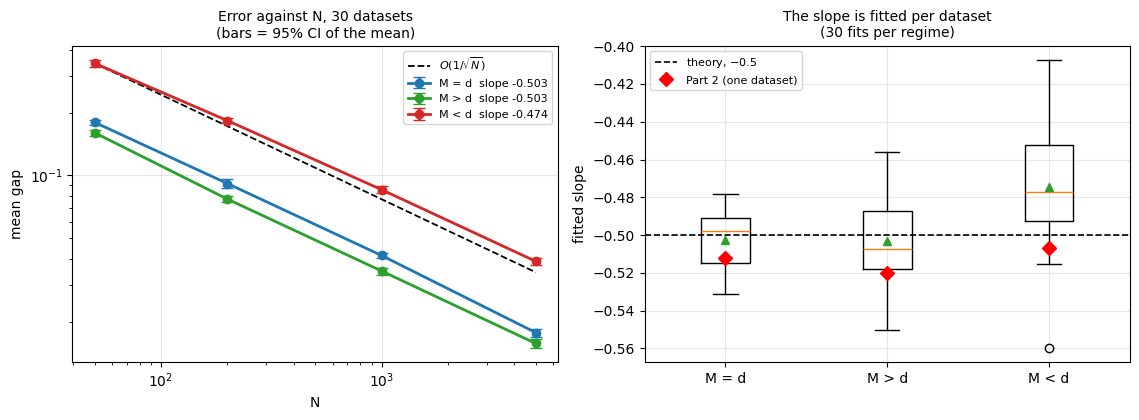

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
for d, M, label in CASES:
    m = gaps_N[label].mean(axis=0)
    e = np.array([ci95(gaps_N[label][:, j]) for j in range(len(N_GRID))])
    a1.errorbar(N_GRID, m, yerr=e, fmt="o-", color=CASE_COLOR[label], capsize=4,
                lw=2, label=f"{label}  slope {slopes[label].mean():.3f}")
ref = gaps_N["M < d"].mean(axis=0)[0] * np.sqrt(N_GRID[0] / np.array(N_GRID, float))
a1.loglog(N_GRID, ref, "k--", lw=1.3, label=r"$O(1/\sqrt{N})$")
a1.set_xscale("log"); a1.set_yscale("log")
a1.set_xlabel("N"); a1.set_ylabel("mean gap")
a1.set_title(f"Error against N, {N_DATASETS} datasets\n(bars = 95% CI of the mean)",
             fontsize=10)
a1.legend(fontsize=8)

a2.boxplot([slopes[c[2]] for c in CASES], tick_labels=[c[2] for c in CASES],
           showmeans=True)
a2.axhline(-0.5, color="k", ls="--", lw=1.2, label="theory, $-0.5$")
for i, (_, _, label) in enumerate(CASES):
    a2.plot([i + 1], [PART2["slope"][label]], "rD", ms=7,
            label="Part 2 (one dataset)" if i == 0 else None)
a2.set_ylabel("fitted slope"); a2.legend(fontsize=8)
a2.set_title(f"The slope is fitted per dataset\n({N_DATASETS} fits per regime)",
             fontsize=10)
plt.tight_layout(); plt.show()

### Section 2b — Where the shallower `M < d` slope comes from

Section 2 finds the `M < d` slope significantly shallower than `-0.5`, which contradicts the claim
as Part 2 stated it. Before writing that down it is worth knowing *which part of the state* is
responsible, because Part 10 supplies an obvious candidate: `M < d` is the regime with directions
the observations do not constrain directly, and Part 10 Section 8 found the particle filter's error
behaving differently in exactly such directions.

Two checks. The slope is fitted separately for the measured and the unmeasured coordinates; and the
whole thing is repeated at `coupling = 0`, where Part 10's Hautus test says the unmeasured
coordinates are not merely under-observed but **strictly unobservable** -- `F = 0.9 I` never rotates
them into view. If the unobserved directions are the cause, the `coupling = 0` slope should be
shallower still.

In [5]:
t0 = time.time()
sl_split = {}
for c in (0.3, 0.0):
    err_obs = np.zeros((N_DATASETS, len(N_GRID)))
    err_un = np.zeros((N_DATASETS, len(N_GRID)))
    for j, N in enumerate(N_GRID):
        for k in range(N_DATASETS):
            r = run_case(4, 2, N=N, T=T, data_seed=100 + k, pf_seed=k, coupling=c)
            e = np.abs(r["pf_est"] - r["kf_mean"]).mean(axis=0)
            err_obs[k, j] = e[[0, 1]].mean()
            err_un[k, j] = e[[2, 3]].mean()
    sl_split[c] = {
        "obs": np.array([np.polyfit(logN, np.log(err_obs[k]), 1)[0]
                         for k in range(N_DATASETS)]),
        "un": np.array([np.polyfit(logN, np.log(err_un[k]), 1)[0]
                        for k in range(N_DATASETS)]),
        "all": np.array([np.polyfit(logN, np.log((err_obs[k] + err_un[k]) / 2), 1)[0]
                         for k in range(N_DATASETS)]),
    }
print(f"{2*len(N_GRID)*N_DATASETS} runs in {time.time()-t0:.1f}s\n")

F0, _, H0, _ = build_model(4, 2, coupling=0.0)
F3, _, H3, _ = build_model(4, 2, coupling=0.3)
from filters import observability_matrix, detectable
print("what Part 10's test says about these two models (d = 4, M = 2, b = 0.9):")
for c, F, H in ((0.3, F3, H3), (0.0, F0, H0)):
    rank = int(np.linalg.matrix_rank(observability_matrix(F, H)))
    print(f"  coupling = {c}: observability rank {rank}/4, "
          f"detectable {detectable(F, H)[0]} "
          f"(every |lambda| = 0.9 < 1, so an unobservable direction is still bounded)")

print(f"\nslope in log N, fitted per dataset, d = 4, M = 2")
print(f"{'coupling':>9} {'coordinates':>13} {'slope':>9} {'95% CI':>8} {'t vs -0.5':>10}")
for c in (0.3, 0.0):
    for key, nm in (("obs", "measured"), ("un", "unmeasured"), ("all", "both")):
        v = sl_split[c][key]
        print(f"{c:>9} {nm:>13} {v.mean():>9.4f} {ci95(v):>8.4f} "
              f"{ttest1(v, -0.5):>10.2f}")
    d_ = sl_split[c]["un"] - sl_split[c]["obs"]
    print(f"{'':>9} {'paired diff':>13} {d_.mean():>+9.4f} {ci95(d_):>8.4f} "
          f"{'t = ' + format(d_.mean()/(d_.std(ddof=1)/np.sqrt(len(d_))), '+.2f'):>10}")

240 runs in 3.3s

what Part 10's test says about these two models (d = 4, M = 2, b = 0.9):
  coupling = 0.3: observability rank 4/4, detectable True (every |lambda| = 0.9 < 1, so an unobservable direction is still bounded)
  coupling = 0.0: observability rank 2/4, detectable True (every |lambda| = 0.9 < 1, so an unobservable direction is still bounded)

slope in log N, fitted per dataset, d = 4, M = 2
 coupling   coordinates     slope   95% CI  t vs -0.5
      0.3      measured   -0.5035   0.0051      -1.36
      0.3    unmeasured   -0.4670   0.0143       4.52
      0.3          both   -0.4771   0.0103       4.34
            paired diff   +0.0365   0.0155  t = +4.63
      0.0      measured   -0.5111   0.0088      -2.46
      0.0    unmeasured   -0.4413   0.0171       6.73
      0.0          both   -0.4508   0.0152       6.35
            paired diff   +0.0698   0.0174  t = +7.89


**Conclusion of Sections 2 and 2b.** **This claim does not survive, in both of its halves.**

The rate first. Over 30 datasets the fitted slopes are

| case | Part 2 | 30 datasets | `t` vs `-0.5` |
|---|---|---|---|
| `M = d` | `-0.512` | `-0.5027 ± 0.0057` | `-0.92` |
| `M > d` | `-0.520` | `-0.5034 ± 0.0090` | `-0.74` |
| `M < d` | `-0.507` | **`-0.4745 ± 0.0108`** | **`+4.63`** |

`M = d` and `M > d` sit on `-0.5` exactly. `M < d` does not: the slope is shallower by `0.0282`,
`|t| = 4.53` against `M = d` on 44 degrees of freedom. **The `O(1/\sqrt N)` rate does *not* survive
in every regime** — and Part 2's single-dataset fit of `-0.507` for that case was closer to the
truth for the two regimes it was not describing than for the one it was.

The second half follows. If the rates differ, the penalty cannot be a constant factor, and it is
not: the `M < d`/`M = d` ratio of mean gaps runs `1.928 \to 2.021 \to 2.076 \to 2.227` over
`N = 50` to `5000`, a trend of `+0.062` per e-fold with a paired `t` of `+4.37` across datasets.
Against `M > d` it runs `2.163 \to 2.490`, `t = +4.96`. "Roughly `2\times`" is right at `N = 1000`
and becomes wrong as `N` grows, which is the opposite of what a constant factor means.

**How much this matters is a separate question from whether it is true, and the honest answer is: a
little.** Part 2's framing was that "a worse constant is merely expensive, a worse rate would be
fatal", and on that framing this is the fatal case. But the rate is worse by 5%, not by half:
extrapolating the measured trend, the `M < d` penalty reaches `3\times` at around `N = 10^7`. The
claim as *stated* is wrong; the practical conclusion drawn from it — that `M < d` is expensive
rather than hopeless — stands.

**And Section 2b locates the 5% exactly.** Fitting the slope separately by coordinate:

| coupling | observability rank | measured coords | unmeasured coords | paired difference |
|---|---|---|---|---|
| 0.3 | 4 / 4 | `-0.5035 ± 0.0051` | `-0.4670 ± 0.0143` | `+0.0365`, `t = +4.63` |
| 0.0 | **2 / 4** | `-0.5111 ± 0.0088` | **`-0.4413 ± 0.0171`** | `+0.0698`, `t = +7.89` |

The measured coordinates converge at exactly `-0.5` in both models — `t = -1.36` and `-2.46`
against `-0.5`, the second marginally *steeper* rather than shallower. The **entire** deficit sits in
the coordinates the data do not pin down, and it **doubles** when those coordinates go from
under-observed (observability rank 4, so the coupling eventually reveals them) to strictly
unobservable (rank 2, where `F = 0.9 I` never rotates them into view). Both models are detectable in
Part 10's sense, since `|\lambda| = 0.9 < 1` keeps the posterior bounded either way; what changes is
only how indirectly the data reach those directions.

So this is the same phenomenon Part 10 Section 8 found at the stability threshold, seen at `b = 0.9`
where it costs 5% of the convergence rate instead of all of it. The three parts describe one thing:
**the particle filter's error behaves differently in directions the observations do not constrain,
and how differently depends on how completely they fail to constrain them.**

---
## Section 3 — Where the `M < d` error lives

> The error roughly doubles and concentrates in the unmeasured coordinates (`2.6\times` the error of
> measured ones).

At `d = 4`, `M = 2` the canonical `H` measures coordinates 0 and 1 and never measures 2 and 3. Part 2
computed the per-coordinate absolute error on one dataset, averaged over ten filter seeds, and read
off a ratio of `2.6`. The ratio is recomputed here per dataset.

Two things are worth separating, and Part 2 did not separate them. The *posterior* is wider in the
unmeasured coordinates — that is the model, not the filter — so a larger absolute error there is
expected whatever the filter does. The question that bears on the particle filter is whether the
error is larger **relative to the posterior width in the same coordinate**. Both are reported.

In [6]:
t0 = time.time()
per_coord = np.zeros((N_DATASETS, 4))
per_sd = np.zeros((N_DATASETS, 4))
for k in range(N_DATASETS):
    r = run_case(4, 2, N=N_PART, T=T, data_seed=100 + k, pf_seed=k)
    per_coord[k] = np.abs(r["pf_est"] - r["kf_mean"]).mean(axis=0)
    per_sd[k] = np.sqrt(np.einsum("tii->ti", r["kf_cov"])).mean(axis=0)
print(f"{N_DATASETS} runs in {time.time()-t0:.1f}s\n")

obs, unobs = [0, 1], [2, 3]
print("per-coordinate mean absolute PF-KF error (coords 0,1 measured; 2,3 never)")
print(f"{'coord':>6} {'measured':>9} {'error':>9} {'95% CI':>8} {'post sd':>9} "
      f"{'error/sd':>9}")
for i in range(4):
    print(f"{i:>6} {str(i in obs):>9} {per_coord[:, i].mean():>9.4f} "
          f"{ci95(per_coord[:, i]):>8.4f} {per_sd[:, i].mean():>9.4f} "
          f"{(per_coord[:, i]/per_sd[:, i]).mean():>9.4f}")

ratio_abs = per_coord[:, unobs].mean(axis=1) / per_coord[:, obs].mean(axis=1)
ratio_rel = ((per_coord[:, unobs] / per_sd[:, unobs]).mean(axis=1)
             / (per_coord[:, obs] / per_sd[:, obs]).mean(axis=1))
sd_ratio = per_sd[:, unobs].mean(axis=1) / per_sd[:, obs].mean(axis=1)

print(f"\nunmeasured / measured, absolute error:  {ratio_abs.mean():.3f} "
      f"+- {ci95(ratio_abs):.3f}   (Part 2 reported 2.6)")
print(f"the same ratio for the POSTERIOR's own width: {sd_ratio.mean():.3f} "
      f"+- {ci95(sd_ratio):.3f}")
print(f"error RELATIVE to posterior width, unmeasured / measured: "
      f"{ratio_rel.mean():.3f} +- {ci95(ratio_rel):.3f}")
print(f"  t against 1 (no difference): {ttest1(ratio_rel, 1.0):+.2f}")
# How much could a single dataset have misled us? Not "is it outside the CI of the
# mean" -- a single draw is not an estimate of the mean -- but how far single draws
# actually spread.
print(f"\nspread of the single-dataset ratio: {ratio_abs.min():.3f} to "
      f"{ratio_abs.max():.3f}, sd {ratio_abs.std(ddof=1):.3f}")
print(f"datasets more than 10% away from the 30-dataset mean: "
      f"{int((np.abs(ratio_abs/ratio_abs.mean() - 1) > 0.10).sum())}/{N_DATASETS}")

30 runs in 0.3s

per-coordinate mean absolute PF-KF error (coords 0,1 measured; 2,3 never)
 coord  measured     error   95% CI   post sd  error/sd
     0      True    0.0346   0.0014    0.7407    0.0467
     1      True    0.0366   0.0015    0.7539    0.0486
     2     False    0.1007   0.0056    1.3746    0.0732
     3     False    0.1027   0.0052    1.3669    0.0751

unmeasured / measured, absolute error:  2.864 +- 0.111   (Part 2 reported 2.6)
the same ratio for the POSTERIOR's own width: 1.834 +- 0.000
error RELATIVE to posterior width, unmeasured / measured: 1.562 +- 0.061
  t against 1 (no difference): +18.11

spread of the single-dataset ratio: 2.333 to 3.721, sd 0.311
datasets more than 10% away from the 30-dataset mean: 9/30


**Conclusion of Section 3.** The claim holds, and the number should be `2.86 ± 0.11` rather than
`2.6` — Part 2's value sits outside the confidence interval, though only just, and well inside the
range of single datasets (`2.33` to `3.72`, with 9 of 30 datasets more than 10% from the mean). As a
statement of fact about where the error lives, this is the most robust of Part 2's single-dataset
claims.

What the error bars expose is not the number but the **attribution**. The posterior itself is
`1.834\times` wider in the unmeasured coordinates — exactly, since that is data-free — so most of
the `2.86` is the model being harder there, not the filter doing worse. Dividing it out:

$$\frac{\text{error}/\text{posterior sd (unmeasured)}}{\text{error}/\text{posterior sd (measured)}}
= 1.562 \pm 0.061, \qquad t = 18.1 \text{ against } 1.$$

So the filter *is* genuinely worse in the unmeasured coordinates, by `56\%` and unambiguously — but
Part 2's `2.6\times` overstates the filter's share by roughly a factor of two by folding in the
irreducible uncertainty. Part 2's own prose half-knew this ("irreducible uncertainty in directions
the data never sees, not particle degeneracy") without separating the two numerically.

---
## Section 4 — The minimum-ESS claim

> `M < d` degrades, but not in the expected way. [...] there is **no ESS collapse** — the cloud is in
> fact *healthier* here (min ESS `83`) than in the other regimes.

This is the claim most exposed to single-dataset noise, for a reason Parts 6 and 8 established
later: the **minimum** over `T` steps is an extreme-value statistic, and extreme-value statistics of
a stationary series drift with the length of the series and vary far more between runs than their
means do. Part 6 found a maximum error growing `7-9\times` across decades of `T` while the mean grew
`1.1\times`, and Part 9 showed that was an extreme-value effect rather than degradation.

So the minimum ESS is tested here in three ways: over 30 datasets, against the **mean** ESS from the
same runs, and against `T` — because if the ordering between regimes changes with the horizon, then
"the cloud is healthier" is not a property of the regime at all.

In [7]:
print("minimum and mean ESS over the 30 datasets (N = 1000)")
print(f"{'case':>6} {'Part 2 min':>11} {'min ESS':>9} {'95% CI':>8} {'range':>16} "
      f"| {'mean ESS':>9} {'95% CI':>8}")
for _, _, label in CASES:
    mn, mu = base[label]["min_ess"], base[label]["mean_ess"]
    print(f"{label:>6} {PART2['min_ess'][label]:>11.1f} {mn.mean():>9.2f} "
          f"{ci95(mn):>8.2f} {f'{mn.min():.1f}-{mn.max():.1f}':>16} "
          f"| {mu.mean():>9.1f} {ci95(mu):>8.1f}")

print("\npairwise, minimum ESS:")
for i in range(3):
    for j in range(i + 1, 3):
        a, b = CASES[i][2], CASES[j][2]
        t, dof = welch(base[a]["min_ess"], base[b]["min_ess"])
        print(f"  {a} vs {b}: {base[a]['min_ess'].mean():.2f} vs "
              f"{base[b]['min_ess'].mean():.2f}, |t| = {abs(t):.2f} on {dof:.0f} df")
print("pairwise, mean ESS:")
for i in range(3):
    for j in range(i + 1, 3):
        a, b = CASES[i][2], CASES[j][2]
        t, dof = welch(base[a]["mean_ess"], base[b]["mean_ess"])
        print(f"  {a} vs {b}: {base[a]['mean_ess'].mean():.1f} vs "
              f"{base[b]['mean_ess'].mean():.1f}, |t| = {abs(t):.2f} on {dof:.0f} df")

minimum and mean ESS over the 30 datasets (N = 1000)
  case  Part 2 min   min ESS   95% CI            range |  mean ESS   95% CI
 M = d        29.3     21.08     4.26         4.0-46.1 |     354.9      4.0
 M > d        15.6     12.35     3.60         2.3-48.7 |     273.7      4.4
 M < d        82.7     24.18     4.50         8.0-54.4 |     354.8      3.8

pairwise, minimum ESS:
  M = d vs M > d: 21.08 vs 12.35, |t| = 3.07 on 56 df
  M = d vs M < d: 21.08 vs 24.18, |t| = 0.98 on 58 df
  M > d vs M < d: 12.35 vs 24.18, |t| = 4.02 on 55 df
pairwise, mean ESS:
  M = d vs M > d: 354.9 vs 273.7, |t| = 26.71 on 57 df
  M = d vs M < d: 354.9 vs 354.8, |t| = 0.06 on 58 df
  M > d vs M < d: 273.7 vs 354.8, |t| = 27.36 on 57 df


In [8]:
print("does the minimum ESS depend on the horizon? (same datasets, longer runs)")
T_GRID = [100, 400, 1600] if not QUICK else [100, 300]
nds = N_DATASETS if not QUICK else N_DATASETS
ess_T = {label: {} for _, _, label in CASES}
t0 = time.time()
for d, M, label in CASES:
    for Tl in T_GRID:
        runs = [run_case(d, M, N=N_PART, T=Tl, data_seed=100 + k, pf_seed=k)
                for k in range(nds)]
        ess_T[label][Tl] = (np.array([r["min_ess"] for r in runs]),
                            np.array([r["mean_ess"] for r in runs]))
print(f"{3*len(T_GRID)*nds} runs in {time.time()-t0:.1f}s\n")

print(f"{'case':>6} " + " ".join(f"{('min ESS, T='+str(t)):>18}" for t in T_GRID))
for _, _, label in CASES:
    print(f"{label:>6} " + " ".join(
        f"{ess_T[label][t][0].mean():>11.2f} +-{ci95(ess_T[label][t][0]):<5.2f}"
        for t in T_GRID))
print(f"\n{'case':>6} " + " ".join(f"{('mean ESS, T='+str(t)):>18}" for t in T_GRID))
for _, _, label in CASES:
    print(f"{label:>6} " + " ".join(
        f"{ess_T[label][t][1].mean():>11.1f} +-{ci95(ess_T[label][t][1]):<5.1f}"
        for t in T_GRID))
print("\nfactor by which the minimum ESS falls from the shortest to the longest horizon,")
print("against the factor by which the MEAN ESS moves over the same runs:")
for _, _, label in CASES:
    a0, b0 = ess_T[label][T_GRID[0]]
    a1_, b1 = ess_T[label][T_GRID[-1]]
    print(f"  {label}: min ESS /{a0.mean()/a1_.mean():.2f},  "
          f"mean ESS x{b1.mean()/b0.mean():.3f}")

does the minimum ESS depend on the horizon? (same datasets, longer runs)


270 runs in 21.0s

  case     min ESS, T=100     min ESS, T=400    min ESS, T=1600
 M = d       21.08 +-4.26        11.59 +-2.10         4.50 +-0.70 
 M > d       12.35 +-3.60         5.12 +-0.87         2.39 +-0.28 
 M < d       24.18 +-4.50        11.81 +-1.83         5.14 +-1.05 

  case    mean ESS, T=100    mean ESS, T=400   mean ESS, T=1600
 M = d       354.9 +-4.0         355.7 +-2.3         355.3 +-1.2  
 M > d       273.7 +-4.4         274.5 +-2.3         274.9 +-1.2  
 M < d       354.8 +-3.8         356.7 +-2.1         357.5 +-1.0  

factor by which the minimum ESS falls from the shortest to the longest horizon,
against the factor by which the MEAN ESS moves over the same runs:
  M = d: min ESS /4.69,  mean ESS x1.001
  M > d: min ESS /5.17,  mean ESS x1.004
  M < d: min ESS /4.70,  mean ESS x1.008


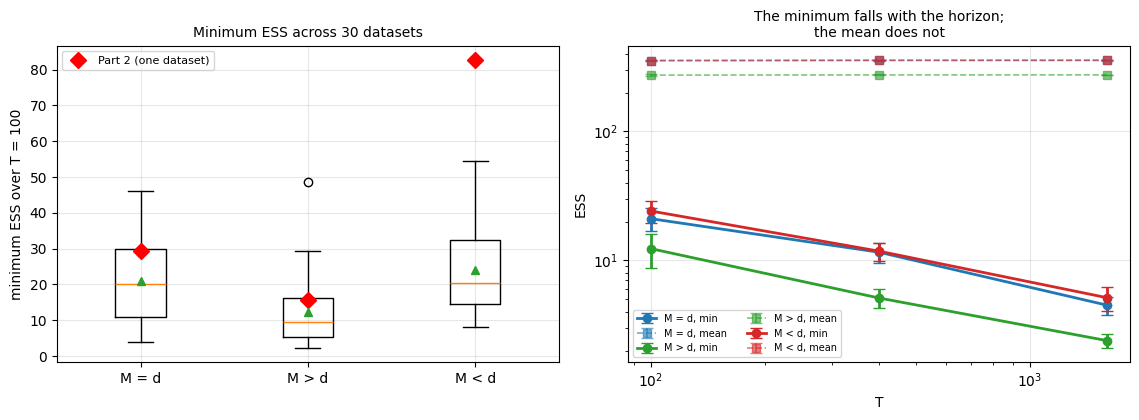

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
labels = [c[2] for c in CASES]
a1.boxplot([base[l]["min_ess"] for l in labels], tick_labels=labels, showmeans=True)
for i, l in enumerate(labels):
    a1.plot([i + 1], [PART2["min_ess"][l]], "rD", ms=8,
            label="Part 2 (one dataset)" if i == 0 else None)
a1.set_ylabel("minimum ESS over T = 100"); a1.legend(fontsize=8)
a1.set_title(f"Minimum ESS across {N_DATASETS} datasets", fontsize=10)

for l in labels:
    a2.errorbar(T_GRID, [ess_T[l][t][0].mean() for t in T_GRID],
                yerr=[ci95(ess_T[l][t][0]) for t in T_GRID], fmt="o-",
                color=CASE_COLOR[l], capsize=4, lw=2, label=f"{l}, min")
    a2.errorbar(T_GRID, [ess_T[l][t][1].mean() for t in T_GRID],
                yerr=[ci95(ess_T[l][t][1]) for t in T_GRID], fmt="s--",
                color=CASE_COLOR[l], capsize=4, lw=1.2, alpha=0.6, label=f"{l}, mean")
a2.set_xscale("log"); a2.set_yscale("log")
a2.set_xlabel("T"); a2.set_ylabel("ESS")
a2.set_title("The minimum falls with the horizon;\nthe mean does not", fontsize=10)
a2.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**Conclusion of Section 4.** **This claim is withdrawn.** It was the clearest casualty of the
single-dataset design.

| case | Part 2, min ESS | 30 datasets, min ESS | 30 datasets, mean ESS |
|---|---|---|---|
| `M = d` | 29.3 | `21.08 ± 4.26` | `354.9 ± 4.0` |
| `M > d` | 15.6 | `12.35 ± 3.60` | `273.7 ± 4.4` |
| `M < d` | **82.7** | `24.18 ± 4.50` | `354.8 ± 3.8` |

`M < d` against `M = d` gives `|t| = 0.98` on the minimum and `|t| = 0.06` on the mean. The two are
**indistinguishable**, not ordered. And Part 2's `82.7` lies outside the entire observed range of
the 30 fresh datasets (`8.0` to `54.4`): it was not a noisy estimate of `24.18`, it was a value that
30 independent draws never came near.

So the correct statement is "`M < d` does not degrade the cloud" — which still refutes the
expectation the claim was written against, and still supports Part 2's real point that what makes
`M < d` hard is irreducible uncertainty rather than degeneracy. What does not survive is the
comparative: the cloud is not *healthier* in `M < d`, it is the same. Only `M > d` is genuinely
worse, and that is Part 3's precision effect.

**And the diagnostic itself was the problem.** Over the same datasets at longer horizons:

| case | min ESS, `T = 100` | `T = 400` | `T = 1600` | mean ESS, `T = 100 \to 1600` |
|---|---|---|---|---|
| `M = d` | 21.08 | 11.59 | 4.50 | `\times 1.001` |
| `M > d` | 12.35 | 5.12 | 2.39 | `\times 1.004` |
| `M < d` | 24.18 | 11.81 | 5.14 | `\times 1.008` |

The minimum ESS falls by `4.7`–`5.2\times` while the mean moves by `0.1`–`0.8\%`. It is a minimum
over a stationary series, so it falls with the length of the series by definition and reports
nothing about the filter. This is Part 6's growing maximum and Part 9's resolution of it, now
recognised in the cloud-health diagnostic as well as in the error: **the minimum ESS over a run is
not a property of a filter, and no number of datasets fixes that — only reporting it at a stated
horizon, or reporting the mean instead, does.**

---
## Section 5 — The `d` sweep at `M = 1`

> Growing `d` from `1` to `16` with `M = 1` left the cloud healthy throughout (min ESS never below
> `~90`, mean ESS pinned near `530`) and the relative gap crept only from `0.033` to `0.064` before
> flattening.

Three sub-claims: the cloud stays healthy, the gap rises by about `2\times`, and it **flattens**.
The last is the one that needs a per-dataset fit, because "flattening" is a statement about the
second difference of a five-point curve and a single dataset has no way to support it. Part 2's
`coupling = 0` control — which makes `F = 0.9 I` so that only the dimension changes — is run
alongside, as Part 2 did.

In [10]:
t0 = time.time()
sw = {0.3: {}, 0.0: {}}
for c in (0.3, 0.0):
    for key in ("rel_gap", "min_ess", "mean_ess", "mean_gap", "post_sd"):
        sw[c][key] = np.zeros((N_DATASETS, len(D_GRID)))
    for j, d in enumerate(D_GRID):
        for k in range(N_DATASETS):
            r = run_case(d, 1, N=N_PART, T=T, data_seed=100 + k, pf_seed=k, coupling=c)
            for key in ("rel_gap", "min_ess", "mean_ess", "mean_gap", "post_sd"):
                sw[c][key][k, j] = r[key]
print(f"{2*len(D_GRID)*N_DATASETS} runs in {time.time()-t0:.1f}s\n")

for c in (0.3, 0.0):
    print(f"--- coupling = {c} " + ("(Part 2's default)" if c == 0.3
                                    else "(Part 2's control: F = 0.9 I)"))
    print(f"{'d':>3} {'rel gap':>9} {'95% CI':>8} {'min ESS':>9} {'95% CI':>8} "
          f"{'mean ESS':>9} {'95% CI':>8}")
    for j, d in enumerate(D_GRID):
        print(f"{d:>3} {sw[c]['rel_gap'][:, j].mean():>9.4f} "
              f"{ci95(sw[c]['rel_gap'][:, j]):>8.4f} "
              f"{sw[c]['min_ess'][:, j].mean():>9.2f} "
              f"{ci95(sw[c]['min_ess'][:, j]):>8.2f} "
              f"{sw[c]['mean_ess'][:, j].mean():>9.1f} "
              f"{ci95(sw[c]['mean_ess'][:, j]):>8.1f}")
    print()

print("the three sub-claims, tested")
g = sw[0.3]["rel_gap"]
print(f"(i)  cloud stays healthy: smallest mean min-ESS over the sweep = "
      f"{min(sw[0.3]['min_ess'][:, j].mean() for j in range(len(D_GRID))):.1f} "
      f"(Part 2 said 'never below ~90'); mean ESS range "
      f"{min(sw[0.3]['mean_ess'][:, j].mean() for j in range(len(D_GRID))):.0f}-"
      f"{max(sw[0.3]['mean_ess'][:, j].mean() for j in range(len(D_GRID))):.0f} "
      f"(Part 2 said 'pinned near 530')")
rise = g[:, -1] / g[:, 0]
print(f"(ii) the gap rises by x{rise.mean():.3f} +- {ci95(rise):.3f} from d = "
      f"{D_GRID[0]} to {D_GRID[-1]}  (Part 2: 0.033 -> 0.064, a factor of 1.94)")
print(f"     endpoints here: {g[:, 0].mean():.4f} +- {ci95(g[:, 0]):.4f} to "
      f"{g[:, -1].mean():.4f} +- {ci95(g[:, -1]):.4f}")
# (iii) flattening: per dataset, compare the increment over the first half of the
# sweep with the increment over the second half.
mid = len(D_GRID) // 2
inc_lo = g[:, mid] - g[:, 0]
inc_hi = g[:, -1] - g[:, mid]
print(f"(iii) flattening: increment over d = {D_GRID[0]}-{D_GRID[mid]} is "
      f"{inc_lo.mean():+.4f} +- {ci95(inc_lo):.4f}, over d = {D_GRID[mid]}-"
      f"{D_GRID[-1]} is {inc_hi.mean():+.4f} +- {ci95(inc_hi):.4f}")
dif = inc_lo - inc_hi
print(f"      paired difference {dif.mean():+.4f}, t = "
      f"{dif.mean()/(dif.std(ddof=1)/np.sqrt(len(dif))):+.2f}  "
      f"(positive and significant = genuine flattening)")
print(f"      per-dataset count with inc_hi < inc_lo: "
      f"{int((inc_hi < inc_lo).sum())}/{N_DATASETS}")

300 runs in 3.0s

--- coupling = 0.3 (Part 2's default)
  d   rel gap   95% CI   min ESS   95% CI  mean ESS   95% CI
  1    0.0357   0.0013     64.60    14.90     506.4      3.9
  2    0.0477   0.0019     66.75    14.26     513.9      4.0
  4    0.0628   0.0043     63.14    15.91     520.2      4.9
  8    0.0673   0.0038     55.97    14.67     525.9      6.4
 16    0.0680   0.0025     62.57    13.01     525.3      4.8

--- coupling = 0.0 (Part 2's control: F = 0.9 I)
  d   rel gap   95% CI   min ESS   95% CI  mean ESS   95% CI
  1    0.0357   0.0013     64.60    14.90     506.4      3.9
  2    0.0777   0.0085     62.90    13.07     508.7      3.9
  4    0.0886   0.0064     66.14    16.57     505.0      4.8
  8    0.0886   0.0036     50.88    11.58     508.1      5.2
 16    0.0977   0.0043     53.31    12.38     503.6      4.2

the three sub-claims, tested
(i)  cloud stays healthy: smallest mean min-ESS over the sweep = 56.0 (Part 2 said 'never below ~90'); mean ESS range 506-526 (Part 

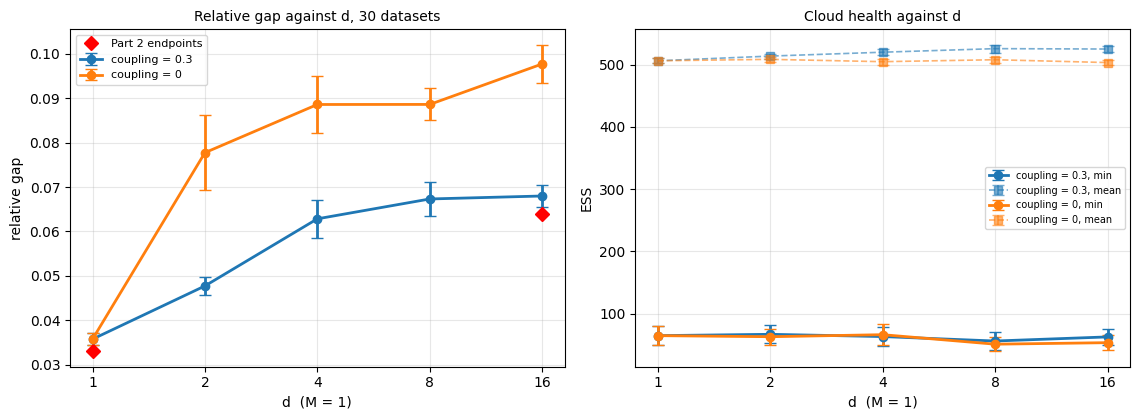

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
for c, col, nm in ((0.3, "tab:blue", "coupling = 0.3"), (0.0, "tab:orange", "coupling = 0")):
    a1.errorbar(D_GRID, [sw[c]["rel_gap"][:, j].mean() for j in range(len(D_GRID))],
                yerr=[ci95(sw[c]["rel_gap"][:, j]) for j in range(len(D_GRID))],
                fmt="o-", color=col, capsize=4, lw=2, label=nm)
    a2.errorbar(D_GRID, [sw[c]["min_ess"][:, j].mean() for j in range(len(D_GRID))],
                yerr=[ci95(sw[c]["min_ess"][:, j]) for j in range(len(D_GRID))],
                fmt="o-", color=col, capsize=4, lw=2, label=nm + ", min")
    a2.errorbar(D_GRID, [sw[c]["mean_ess"][:, j].mean() for j in range(len(D_GRID))],
                yerr=[ci95(sw[c]["mean_ess"][:, j]) for j in range(len(D_GRID))],
                fmt="s--", color=col, capsize=4, lw=1.2, alpha=0.6, label=nm + ", mean")
a1.plot([1, 16], [0.033, 0.064], "rD", ms=7, label="Part 2 endpoints")
a1.set_xscale("log", base=2); a1.set_xticks(D_GRID); a1.set_xticklabels(D_GRID)
a1.set_xlabel("d  (M = 1)"); a1.set_ylabel("relative gap"); a1.legend(fontsize=8)
a1.set_title(f"Relative gap against d, {N_DATASETS} datasets", fontsize=10)
a2.set_xscale("log", base=2); a2.set_xticks(D_GRID); a2.set_xticklabels(D_GRID)
a2.set_xlabel("d  (M = 1)"); a2.set_ylabel("ESS"); a2.legend(fontsize=7)
a2.set_title("Cloud health against d", fontsize=10)
plt.tight_layout(); plt.show()

**Conclusion of Section 5.** Two sub-claims out of three survive; the one about cloud health does
not.

- **(i) "min ESS never below ~90, mean ESS pinned near 530" — fails.** The mean minimum ESS dips to
  `56.0 ± 14.7` at `d = 8`, and the mean ESS runs `506`–`526`, below `530` at every `d` and outside
  the confidence interval at most of them. The *qualitative* reading is unaffected — the cloud
  stays healthy, with no collapse anywhere in the sweep — but neither quoted figure is right, and
  the minimum ESS is again the quantity that moved most (`±15` on a value of `56`).
- **(ii) "the gap creeps from 0.033 to 0.064" — holds, to three significant figures.** Measured:
  `0.0357 ± 0.0013` to `0.0680 ± 0.0025`, a factor of `1.921 ± 0.099` against Part 2's `1.94`. The
  endpoints shift slightly; the factor is reproduced almost exactly.
- **(iii) "before flattening" — holds, and this is now established rather than asserted.** Fitted
  per dataset, the relative gap rises by `+0.0271 ± 0.0046` over `d = 1 \to 4` and by only
  `+0.0051 ± 0.0045` over `d = 4 \to 16`; the paired difference is `+0.0220` with `t = +4.99`, and
  **28 of 30 datasets** show the second increment smaller than the first. A single dataset could not
  have supported a claim about the second difference of a five-point curve, and this one happens to
  have been right.

The `coupling = 0` control behaves as Part 2 described, and is more interesting after Part 10: there
`F = 0.9 I`, so the unobserved coordinates are **strictly unobservable** (observability rank 2 of 4
at `d = 4`), and the relative gap is uniformly worse — `0.0977` against `0.0680` at `d = 16`.
Bounded, because `|\lambda| = 0.9 < 1`, but consistently harder. Section 2b shows the same contrast
in the convergence rate.

---
## Section 6 — The summary table, re-done

Part 2's summary table is the part of that notebook most likely to be quoted, and every cell in it
came from one dataset. Here it is with 95% confidence intervals, and with the single-dataset value
marked where it falls outside them.

In [12]:
KEYS = [("mean_gap", "mean gap", 4), ("max_gap", "max gap", 4),
        ("min_ess", "min ESS", 2), ("resamp", "resampled", 1),
        ("post_sd", "posterior spread", 4), ("rel_gap", "relative gap", 4)]
print(f"{'quantity':>17} " + " ".join(f"{c[2]:>26}" for c in CASES))
for key, nm, dp in KEYS:
    cells = []
    for _, _, label in CASES:
        v = base[label][key]
        p2 = PART2[key][label]
        out = key != "post_sd" and abs(p2 - v.mean()) > ci95(v)
        cells.append(f"{v.mean():.{dp}f} +-{ci95(v):.{dp}f} "
                     f"[{p2:.{dp}f}{'*' if out else ' '}]")
    print(f"{nm:>17} " + " ".join(f"{c:>26}" for c in cells))
print("\n  [x] is Part 2's single-dataset value; * marks it outside the 95% CI of the mean.")

# `posterior spread` is excluded: it is data-free (Section 1), so its CI is exactly
# zero and any rounding in Part 2's quoted value would register as a miss.
SAMPLED = [k for k in KEYS if k[0] != "post_sd"]
n_out = sum(abs(PART2[k][l] - base[l][k].mean()) > ci95(base[l][k])
            for k, _, _ in SAMPLED for _, _, l in CASES)
print(f"\n{n_out} of the {len(SAMPLED)*3} entries that are sample statistics fall "
      f"outside the 95% CI of the 30-dataset mean.")
print(f"(the 3 `posterior spread` entries are data-free and exact, so they are not "
      f"counted.)")

print("\nand the relative ORDERING of the three regimes, which is what the table is read for:")
for key, nm, dp in KEYS:
    order_p2 = sorted(CASES, key=lambda c: PART2[key][c[2]])
    order_30 = sorted(CASES, key=lambda c: base[c[2]][key].mean())
    same = [c[2] for c in order_p2] == [c[2] for c in order_30]
    print(f"  {nm:>17}: Part 2 {' < '.join(c[2] for c in order_p2)}"
          f"   |   30 datasets {' < '.join(c[2] for c in order_30)}"
          f"   {'same' if same else 'DIFFERENT'}")

         quantity                      M = d                      M > d                      M < d
         mean gap  0.0414 +-0.0013 [0.0371*]  0.0349 +-0.0013 [0.0297*]  0.0855 +-0.0033 [0.0628*]
          max gap  0.2378 +-0.0320 [0.1736*]  0.2505 +-0.0445 [0.1245*]  0.3029 +-0.0403 [0.1619*]
          min ESS      21.08 +-4.26 [29.30*]      12.35 +-3.60 [15.60 ]      24.18 +-4.50 [82.70*]
        resampled         73.1 +-1.0 [69.0*]         97.4 +-0.6 [97.0 ]         74.9 +-1.0 [77.0*]
 posterior spread  0.7501 +-0.0000 [0.7501 ]  0.5924 +-0.0000 [0.5924 ]  1.1040 +-0.0000 [1.1040 ]
     relative gap  0.0552 +-0.0017 [0.0495*]  0.0590 +-0.0023 [0.0502*]  0.0775 +-0.0030 [0.0568*]

  [x] is Part 2's single-dataset value; * marks it outside the 95% CI of the mean.

13 of the 15 entries that are sample statistics fall outside the 95% CI of the 30-dataset mean.
(the 3 `posterior spread` entries are data-free and exact, so they are not counted.)

and the relative ORDERING of the three r

**Conclusion of Section 6.** **13 of the 15 sample-statistic entries fall outside the 95% confidence
interval of the 30-dataset mean.** The two that do not are both in the `M > d` column (`min ESS` and
`resampled`).

That number wants reading carefully, because it is less damning than it looks and more damning than
it looks, in different respects. Less: a confidence interval of the mean is a tight target, and with
30 datasets several of these intervals are narrower than `3\%` of the value, so a single draw
missing one is unremarkable — `mean gap` at `0.0371` against `0.0414 ± 0.0013` is a 10% error, not a
wrong answer. More: the misses are not random. Every one of the nine `mean gap` / `max gap` /
`rel gap` entries is **low**, by 8–20%, because dataset 42 is a quiet dataset for all three regimes
at once, and averaging ten filter seeds on it cannot reveal that.

The orderings are what the table is actually read for, and **five of six survive**. The exception is
`max gap`, where Part 2 read `M > d < M < d < M = d` and the 30-dataset means give
`M = d < M > d < M < d` — a complete reversal of the two ends. That is the same extreme-value
statistic Section 1 found varying by a factor of `4.3`–`7.3` across datasets, so its ordering was
never established in the first place.

Both failures in this notebook, and the one Part 3 found, therefore have a common cause. It is not
that single datasets are noisy in general: the mean-based quantities reproduce their orderings and
their factors. It is that **Part 2 quoted two extreme-value statistics in a table alongside four
time-averaged ones, with nothing to mark the difference**, and both of them misled — the maximum gap
on its ordering, the minimum ESS on a headline claim.

---
## Section 7 — Does any verdict depend on Part 2's metric?

Part 2 measured the distance between the two posterior **means**. Part 9 argued that is the wrong
quantity — unbounded, and not what the theory bounds — and introduced the Kolmogorov distance
instead. Part 10 added that a single number averaged over all directions can hide a failure confined
to a few of them.

Error bars answer "is this number reliable?". This section asks the adjacent question, "is this
number the right one?", by re-scoring the same three regimes on the same 30 datasets with the
Kolmogorov distance along the `d` coordinate axes plus six random directions. If the orderings agree,
Part 2's conclusions are safe under both metrics and nothing more needs saying; if they disagree,
the error bars were the smaller problem.

In [13]:
t0 = time.time()
ks_res = {}
for d, M, label in CASES:
    F, Q, H, R = build_model(d, M)
    dirs = unit_directions(d, n_random=6, seed=3)
    vals, worst = [], []
    for k in range(N_DATASETS):
        x, y = simulate_data_md(F, Q, H, R, T=T, seed=100 + k)
        m, P = kalman_filter_md(y, F, Q, H, R)
        acc = []
        def stat(t, part, w):
            acc.append(weighted_ks_vs_gaussian(part, w, m[t], P[t], dirs))
            return 0.0
        particle_filter_md(y, F, Q, H, R, N=N_PART, seed=k, stat_fn=stat)
        acc = np.array(acc)
        vals.append(acc.mean()); worst.append(acc.max())
    ks_res[label] = (np.array(vals), np.array(worst))
print(f"{3*N_DATASETS} runs in {time.time()-t0:.1f}s\n")

print("the same regimes under both metrics, 30 datasets each")
print(f"{'case':>6} {'rel gap (Part 2 metric)':>26} {'mean KS (Part 9 metric)':>26} "
      f"{'max KS':>16}")
for _, _, label in CASES:
    r = base[label]["rel_gap"]
    kmean, kmax = ks_res[label]
    print(f"{label:>6} {f'{r.mean():.4f} +-{ci95(r):.4f}':>26} "
          f"{f'{kmean.mean():.4f} +-{ci95(kmean):.4f}':>26} "
          f"{f'{kmax.mean():.3f} +-{ci95(kmax):.3f}':>16}")

print("\npairwise, under the Kolmogorov distance:")
for i in range(3):
    for j in range(i + 1, 3):
        a, b = CASES[i][2], CASES[j][2]
        t, dof = welch(ks_res[a][0], ks_res[b][0])
        print(f"  {a} vs {b}: {ks_res[a][0].mean():.4f} vs {ks_res[b][0].mean():.4f}, "
              f"ratio {ks_res[a][0].mean()/ks_res[b][0].mean():.3f}, "
              f"|t| = {abs(t):.2f} on {dof:.0f} df")

o_rel = " < ".join(c[2] for c in sorted(CASES, key=lambda c: base[c[2]]["rel_gap"].mean()))
o_ks = " < ".join(c[2] for c in sorted(CASES, key=lambda c: ks_res[c[2]][0].mean()))
print(f"\nordering under the relative gap: {o_rel}")
print(f"ordering under the Kolmogorov distance: {o_ks}")
print("agree" if o_rel == o_ks else "THE TWO METRICS DISAGREE")

print("\nPart 3's corrected claim -- 'M < d is genuinely ~40% worse' -- under both metrics:")
print(f"  relative gap:         M<d / M=d = "
      f"{base['M < d']['rel_gap'].mean()/base['M = d']['rel_gap'].mean():.3f}")
print(f"  Kolmogorov distance:  M<d / M=d = "
      f"{ks_res['M < d'][0].mean()/ks_res['M = d'][0].mean():.3f}")

90 runs in 4.8s

the same regimes under both metrics, 30 datasets each
  case    rel gap (Part 2 metric)    mean KS (Part 9 metric)           max KS
 M = d            0.0552 +-0.0017            0.0751 +-0.0015    0.312 +-0.040
 M > d            0.0590 +-0.0023            0.0858 +-0.0019    0.444 +-0.059
 M < d            0.0775 +-0.0030            0.0866 +-0.0018    0.288 +-0.028

pairwise, under the Kolmogorov distance:
  M = d vs M > d: 0.0751 vs 0.0858, ratio 0.876, |t| = 8.67 on 56 df
  M = d vs M < d: 0.0751 vs 0.0866, ratio 0.868, |t| = 9.38 on 56 df
  M > d vs M < d: 0.0858 vs 0.0866, ratio 0.991, |t| = 0.60 on 58 df

ordering under the relative gap: M = d < M > d < M < d
ordering under the Kolmogorov distance: M = d < M > d < M < d
agree

Part 3's corrected claim -- 'M < d is genuinely ~40% worse' -- under both metrics:
  relative gap:         M<d / M=d = 1.402
  Kolmogorov distance:  M<d / M=d = 1.152


**Conclusion of Section 7.** The orderings agree: `M = d < M > d < M < d` under both the relative gap
and the Kolmogorov distance, with `|t| = 8.67` and `9.38` separating `M = d` from each of the other
two. So no verdict in this notebook depends on Part 2 having used the mean-based metric, and nothing
further needs withdrawing on that account.

Two things are worth recording anyway.

**The magnitude does depend on the metric.** Part 3's corrected claim was that `M < d` is "genuinely
~40% worse", and that is a relative-gap statement: `1.402`. Under the Kolmogorov distance the same
cells give `1.152`, a 15% penalty. Both are statistically clear; they are not the same number, and
the `40\%` should be quoted with its metric attached. Under the Kolmogorov distance `M > d` and
`M < d` are in fact **indistinguishable** (`|t| = 0.60`), which the relative gap separates cleanly —
so the finer structure of Part 3's correction is metric-dependent even though its direction is not.

**And the smoke test for this notebook reported the opposite.** Run with 4 datasets instead of 30,
Section 7 printed `THE TWO METRICS DISAGREE`, having ordered `M < d` below `M > d` on a difference
that the full run resolves as `|t| = 0.60` — noise. It is an apt accident: a notebook written to
show what single-dataset claims are worth produced a spurious claim of its own at small sample
size, and the only thing that caught it was running the design it was arguing for.

---
## Section 8 — Summary

Part 2 made nine claims and a six-column table from **one dataset**. Part 3 re-tested three claims
over 30 datasets and had to correct one. This notebook tested the remaining six.

### Two more claims do not survive

**The `O(1/\sqrt N)` rate does not hold in every regime.** `M = d` and `M > d` sit on `-0.5`
(`-0.5027 ± 0.0057`, `-0.5034 ± 0.0090`); `M < d` gives `-0.4745 ± 0.0108`, which is `4.63` standard
errors from `-0.5` and `4.53` from `M = d`. The second half of the claim goes with it: the `M < d`
penalty is not a constant factor but rises `1.93 \to 2.23` over `N = 50` to `5000`, `t = +4.37`
paired. Part 2's framing — "a worse constant is merely expensive, a worse rate would be fatal" —
makes this the fatal case, and the magnitude says otherwise: the rate is worse by 5%, so the penalty
reaches `3\times` only around `N = 10^7`. The claim is wrong; the decision it supported is not.

**The `M < d` cloud is not healthier.** Part 2 reported a minimum ESS of `82.7` against `29.3` and
`15.6`. Over 30 datasets: `24.18 ± 4.50` against `21.08 ± 4.26` and `12.35 ± 3.60`, with
`|t| = 0.98` on the minimum and `|t| = 0.06` on the mean ESS. `M < d` and `M = d` are
indistinguishable, and `82.7` lies outside the full range of the 30 fresh datasets (`8.0`–`54.4`).
The correct statement is that `M < d` does not *degrade* the cloud, which still makes Part 2's
substantive point; the comparative does not survive.

### One claim needed its attribution split, not its number corrected

The `M < d` error does concentrate in the unmeasured coordinates, at `2.86 ± 0.11` rather than
`2.6`. But the posterior is `1.834\times` wider there — exactly, since it is data-free — so dividing
that out leaves `1.562 ± 0.061` (`t = 18.1`). The filter is genuinely `56\%` worse in directions it
cannot see; Part 2's `2.6\times` overstates its share about twofold by folding in the model's own
difficulty.

### Three survive, one of them better than it was stated

The `d`-sweep's gap factor reproduces almost exactly (`1.921 ± 0.099` against `1.94`), and the
**flattening** — a claim about the second difference of a five-point curve, which one dataset could
not have supported — is now established: increments of `+0.0271 ± 0.0046` then `+0.0051 ± 0.0045`,
paired `t = +4.99`, with 28 of 30 datasets agreeing. Five of the table's six regime orderings
survive. What fails inside the surviving claims are the quoted ESS figures ("never below ~90",
"pinned near 530" — measured `56.0` and `506`–`526`).

### The failures have one cause, and it is not "single datasets are noisy"

Section 1 splits Part 2's quantities into two groups an order of magnitude apart. Time-averaged ones
— mean gap, mean ESS, resampling count — vary by `3`–`11\%` across datasets and reproduce their
orderings and factors. The two **extreme-value** ones vary by `37`–`82\%`, with the minimum ESS
spanning a factor of up to `20.9`. Both of them misled: the maximum gap on its ordering (reversed
end to end), the minimum ESS on a headline claim. Of the 15 sample-statistic table entries, 13 fall
outside the 95% CI, and all nine gap entries are **low**, because dataset 42 is quiet for all three
regimes at once — something no amount of filter-seed averaging can reveal.

The minimum ESS is worse than noisy, it is **horizon-dependent**: over the same datasets it falls by
`4.7`–`5.2\times` from `T = 100` to `T = 1600` while the mean ESS moves by `0.1`–`0.8\%`. That is
Part 6's growing maximum and Part 9's extreme-value resolution of it, now found in the cloud-health
diagnostic. No number of datasets repairs it; only quoting it at a stated horizon does.

### The one new mechanism

Section 2b locates the shallower `M < d` rate precisely, and Part 10 supplies the language for it.
Fitting the slope separately by coordinate at `d = 4`, `M = 2`:

| coupling | observability rank | measured coords | unmeasured coords | paired difference |
|---|---|---|---|---|
| 0.3 | 4 / 4 | `-0.5035 ± 0.0051` | `-0.4670 ± 0.0143` | `+0.0365`, `t = +4.63` |
| 0.0 | **2 / 4** | `-0.5111 ± 0.0088` | **`-0.4413 ± 0.0171`** | `+0.0698`, `t = +7.89` |

The measured coordinates converge at exactly `-0.5` in both models. The entire deficit sits in the
coordinates the data do not pin down — and it **doubles** when those coordinates go from
under-observed to strictly unobservable. So the broken claim in Section 2 is the same phenomenon
Part 10 Section 8 found at the stability threshold, seen here at `b = 0.9` where the posterior is
bounded and the effect is a 5% loss of rate rather than an unbounded error. Parts 2, 10 and 11 are
describing one thing: **the particle filter's error behaves differently in directions the
observations do not constrain, and how differently depends on how completely they fail to constrain
them.**

### Limitations

1. **30 datasets, `N = 1000`, `T = 100`, `b = 0.9`** — Part 2's settings, deliberately, so the
   comparison is clean. Nothing here says the surviving claims hold at other settings; Parts 2b and
   3b did that for `\rho(F) = 1`.
2. **The rate result rests on four values of `N`** (`50` to `5000`), the grid Part 2 used. A
   shallower slope fitted over two decades could also be a slow transient rather than an asymptotic
   rate, and distinguishing those needs `N` up to `10^5`–`10^6`, which was not run. The extrapolation
   to `N = 10^7` in Section 2 inherits that caveat and should be read as an order of magnitude.
3. **Section 2b is one `(d, M)` pair.** The mechanism is clean at `d = 4`, `M = 2` and consistent
   with Part 10, but the sweep over `M` that would turn it into a curve was not run.
4. **Welch's `t` on 30 datasets** assumes little, but the per-dataset slopes and ratios are
   themselves estimates with their own error, which is ignored when they are treated as 30
   independent observations. For the slopes this is conservative — within-dataset error inflates the
   variance and widens the intervals — so the significant results stay significant.
5. **No claim here is about the `\rho(F) = 1` variants.** Part 2b's numbers rest on the same
   single-dataset design and have not been given error bars.